# Milestone 2: Member 1 - Dataset Preparation

**Contribution scope:** dataset acquisition, validation, patient mapping,
reproducible splitting, preprocessing, augmentation, and PyTorch data loaders.
Model implementation, training, and final evaluation are completed by the
other team members using the artifacts produced here.

## Baseline being reproduced

- **Paper:** Ali et al. (2025), *DANet: A Lightweight Dilated Attention
  Network for Malaria Parasite Detection*
- **Baseline variant:** DANet-S with LogSoftMax
- **Paper:** [Scientific Reports](https://doi.org/10.1038/s41598-025-20402-1)
- **Source code:** [asfakali/DANet](https://github.com/asfakali/DANet)
- **Dataset:** [NIH/NLM Malaria Cell Images](https://lhncbc.nlm.nih.gov/LHC-research/LHC-projects/image-processing/malaria-datasheet.html)

## Data protocol

| Component | Implementation | Basis |
|---|---:|---|
| Task | Parasitized vs. uninfected classification | Paper |
| Input | 224 x 224 RGB | Paper |
| Split | 70% train, 10% validation, 20% test | Paper |
| Batch size | 64 | Paper |
| Pixel scaling | 0 to 1 | Paper |
| Rotation | Up to 15 degrees | Paper |
| Horizontal flip | Probability 0.20 | Paper interpretation |
| Vertical flip | Probability 0.20 | Paper interpretation |
| Random seed | 42 | Team reproducibility choice |

The notebook preserves the paper's image-level split for baseline
reproduction. Patient overlap is measured and reported as a limitation.


In [1]:
import random

import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

DATA_DIR = Path("/content/malaria_data")
PROJECT_DIR = Path("/content/drive/MyDrive/malaria_danet")

DATA_DIR.mkdir(parents=True, exist_ok=True)
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset folder:", DATA_DIR)
print("Saved artifacts:", PROJECT_DIR)

Dataset folder: /content/malaria_data
Saved artifacts: /content/drive/MyDrive/malaria_danet


## 1. Dataset acquisition

Download and extract the official NIH/NLM single-cell image dataset.


In [4]:
import subprocess

ZIP_PATH = DATA_DIR / "cell_images.zip"
DATASET_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"

subprocess.run(
    ["wget", "-c", "--show-progress", "-O", str(ZIP_PATH), DATASET_URL],
    check=True,
)

print(f"Downloaded file size: {ZIP_PATH.stat().st_size / 1024**2:.1f} MB")

Downloaded file size: 337.1 MB


In [5]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(DATA_DIR)

print("Extraction complete.")
print("Folders:", sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()))

Extraction complete.
Folders: ['cell_images']


In [6]:
IMAGE_ROOT = DATA_DIR / "cell_images"
CLASS_NAMES = ["Uninfected", "Parasitized"]

for class_name in CLASS_NAMES:
    class_dir = IMAGE_ROOT / class_name
    assert class_dir.is_dir(), f"Missing folder: {class_dir}"
    print(f"{class_name}: {len(list(class_dir.glob('*.png'))):,} images")

Uninfected: 13,779 images
Parasitized: 13,779 images


## 2. Dataset inventory and quality checks

Build the image inventory, verify file integrity, inspect dimensions and
colour modes, and check for exact duplicates.


In [7]:
import pandas as pd

CLASS_TO_LABEL = {"Uninfected": 0, "Parasitized": 1}

image_df = pd.DataFrame([
    {
        "relative_path": path.relative_to(IMAGE_ROOT).as_posix(),
        "class_name": class_name,
        "label": CLASS_TO_LABEL[class_name],
    }
    for class_name in CLASS_NAMES
    for path in sorted((IMAGE_ROOT / class_name).glob("*.png"))
])

print("Total images:", len(image_df))
print("Label mapping:", CLASS_TO_LABEL)
display(image_df.head())

Total images: 27558
Label mapping: {'Uninfected': 0, 'Parasitized': 1}


,relative_path,class_name,label
0,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0
1,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0
2,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0
3,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0
4,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0


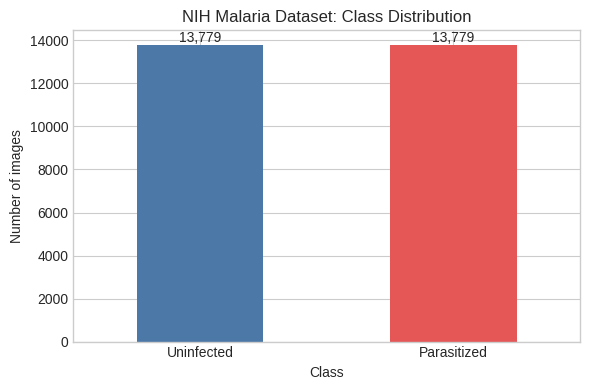

In [8]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

PRIMARY_COLOR = "#4C78A8"
SECONDARY_COLOR = "#E45756"
CLASS_COLORS = {
    "Uninfected": PRIMARY_COLOR,
    "Parasitized": SECONDARY_COLOR,
}

class_counts = image_df["class_name"].value_counts().reindex(CLASS_NAMES)

ax = class_counts.plot(
    kind="bar",
    color=[CLASS_COLORS[name] for name in class_counts.index],
    figsize=(6, 4),
)

ax.set_title("NIH Malaria Dataset: Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)

for index, count in enumerate(class_counts):
    ax.text(index, count + 150, f"{count:,}", ha="center")

plt.tight_layout()
plt.savefig(PROJECT_DIR / "class_distribution.png", dpi=200)
plt.show()


In [9]:
from PIL import Image

bad_images = []

for relative_path in image_df["relative_path"]:
    image_path = IMAGE_ROOT / relative_path

    try:
        with Image.open(image_path) as image:
            image.verify()
    except Exception as error:
        bad_images.append((relative_path, str(error)))

print("Images checked:", len(image_df))
print("Unreadable images:", len(bad_images))

Images checked: 27558
Unreadable images: 0


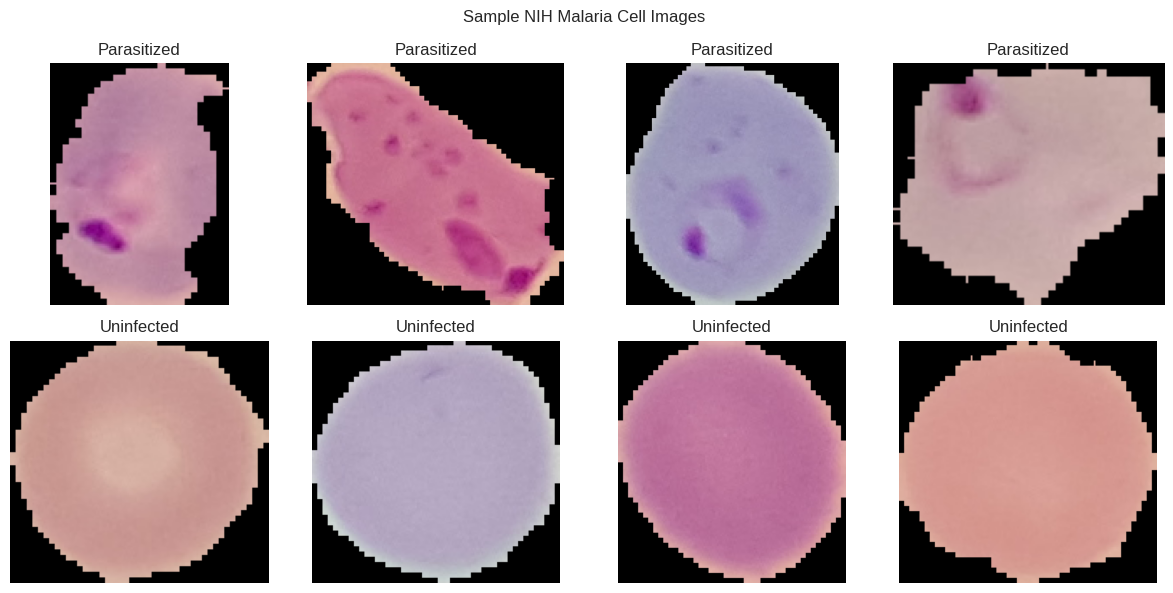

In [10]:
samples = (
    image_df.groupby("class_name", group_keys=False)
    .sample(n=4, random_state=42)
)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    with Image.open(IMAGE_ROOT / row["relative_path"]) as image:
        ax.imshow(image)

    ax.set_title(row["class_name"])
    ax.axis("off")

plt.suptitle("Sample NIH Malaria Cell Images")
plt.tight_layout()
plt.savefig(PROJECT_DIR / "sample_images.png", dpi=200)
plt.show()

In [11]:
from collections import Counter

size_counts = Counter()
mode_counts = Counter()

for relative_path in image_df["relative_path"]:
    with Image.open(IMAGE_ROOT / relative_path) as image:
        size_counts[image.size] += 1
        mode_counts[image.mode] += 1

print("Unique image sizes:", len(size_counts))
print("Minimum width:", min(width for width, height in size_counts))
print("Maximum width:", max(width for width, height in size_counts))
print("Minimum height:", min(height for width, height in size_counts))
print("Maximum height:", max(height for width, height in size_counts))
print("Colour modes:", dict(mode_counts))

Unique image sizes: 1627
Minimum width: 46
Maximum width: 394
Minimum height: 40
Maximum height: 385
Colour modes: {'RGB': 27558}


In [12]:
dimensions = []

for relative_path in image_df["relative_path"]:
    with Image.open(IMAGE_ROOT / relative_path) as image:
        dimensions.append(image.size)

image_df[["width", "height"]] = pd.DataFrame(
    dimensions,
    index=image_df.index,
)

display(image_df[["width", "height"]].describe().round(2))

,width,height
count,27558.00,27558.00
mean,132.49,132.98
std,20.02,20.62
min,46.00,40.00
25%,121.00,121.00
50%,130.00,130.00
75%,142.00,145.00
max,394.00,385.00


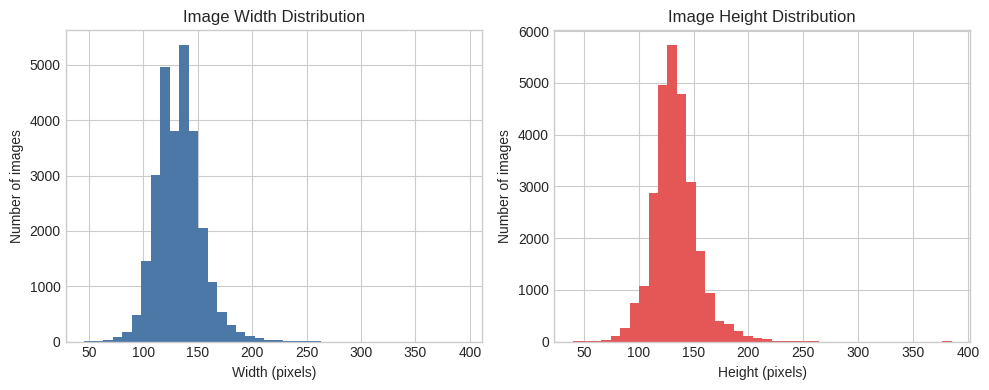

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(image_df["width"], bins=40, color=PRIMARY_COLOR)
axes[0].set_title("Image Width Distribution")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Number of images")

axes[1].hist(image_df["height"], bins=40, color=SECONDARY_COLOR)
axes[1].set_title("Image Height Distribution")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Number of images")

plt.tight_layout()
plt.savefig(PROJECT_DIR / "image_size_distribution.png", dpi=200)
plt.show()


In [14]:
import hashlib

def file_hash(file_path):
    hasher = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            hasher.update(chunk)

    return hasher.hexdigest()

image_df["sha256"] = [
    file_hash(IMAGE_ROOT / path)
    for path in image_df["relative_path"]
]

duplicate_rows = image_df.duplicated("sha256", keep=False).sum()
duplicate_groups = image_df.loc[
    image_df.duplicated("sha256", keep=False),
    "sha256",
].nunique()

cross_class_groups = (
    image_df.groupby("sha256")["label"].nunique().gt(1).sum()
)

print("Rows involved in exact duplicates:", duplicate_rows)
print("Exact duplicate groups:", duplicate_groups)
print("Duplicate groups crossing classes:", cross_class_groups)

Rows involved in exact duplicates: 0
Exact duplicate groups: 0
Duplicate groups crossing classes: 0


### Dataset validation findings

- The dataset is perfectly balanced: 13,779 images per class.
- All 27,558 files are readable RGB images.
- Image dimensions vary substantially, which justifies resizing before
  batching.
- No byte-identical duplicate files were detected within or across classes.
- The visual samples show the staining and appearance differences the model
  must learn.


## 3. Official patient mapping and dataset split

Use the official patient-to-cell mappings, then reproduce the paper's
stratified 70/10/20 image-level split. Patient overlap is measured explicitly
and retained as a documented limitation of the reproduction protocol.


In [15]:
mapping_urls = {
    "parasitized": (
        "https://data.lhncbc.nlm.nih.gov/public/Malaria/"
        "patientid_cellmapping_parasitized.csv"
    ),
    "uninfected": (
        "https://data.lhncbc.nlm.nih.gov/public/Malaria/"
        "patientid_cellmapping_uninfected.csv"
    ),
}

for name, url in mapping_urls.items():
    output_path = DATA_DIR / f"{name}_patient_mapping.csv"
    subprocess.run(["wget", "-q", "-O", str(output_path), url], check=True)
    print(name, "mapping downloaded:", output_path.stat().st_size, "bytes")

parasitized mapping downloaded: 761124 bytes
uninfected mapping downloaded: 667059 bytes


In [16]:
import re


def parse_patient_mapping(file_path, class_name):
    records = []

    with open(file_path, "r") as file:
        for line in file:
            line = line.strip()

            if not line:
                continue

            patient_id = line.split(",", 1)[0].strip()
            filenames = re.findall(r"[^,'\"\[\]\s]+\.png", line)

            for filename in filenames:
                records.append(
                    {
                        "filename": filename,
                        "class_name": class_name,
                        "official_patient_id": patient_id,
                    }
                )

    return pd.DataFrame(records)


parasitized_mapping = parse_patient_mapping(
    DATA_DIR / "parasitized_patient_mapping.csv",
    "Parasitized",
)

uninfected_mapping = parse_patient_mapping(
    DATA_DIR / "uninfected_patient_mapping.csv",
    "Uninfected",
)

official_mapping = pd.concat(
    [parasitized_mapping, uninfected_mapping],
    ignore_index=True,
)

print("Mapped images:", len(official_mapping))
print("Unique patients:", official_mapping["official_patient_id"].nunique())
print(
    official_mapping.groupby("class_name").agg(
        images=("filename", "size"),
        patients=("official_patient_id", "nunique"),
    )
)


Mapped images: 27558
Unique patients: 201
             images  patients
class_name                   
Parasitized   13779       151
Uninfected    13779       201


In [17]:
image_df["filename"] = image_df["relative_path"].map(
    lambda path: Path(path).name
)

image_df = image_df.merge(
    official_mapping,
    on=["filename", "class_name"],
    how="left",
    validate="one_to_one",
)

print("Total inventory rows:", len(image_df))
print("Missing patient IDs:", image_df["official_patient_id"].isna().sum())
print("Unique official patient IDs:", image_df["official_patient_id"].nunique())

display(
    image_df[
        ["relative_path", "class_name", "label", "official_patient_id"]
    ].head()
)


Total inventory rows: 27558
Missing patient IDs: 0
Unique official patient IDs: 201


,relative_path,class_name,label,official_patient_id
0,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0,C100P61ThinF
1,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0,C100P61ThinF
2,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0,C100P61ThinF
3,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0,C100P61ThinF
4,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,Uninfected,0,C100P61ThinF


### Patient metadata note

The official mapping files cover every image and contain 201 distinct patient
identifiers, including 151 identifiers associated with parasitized cells.
This differs by one from the commonly cited dataset summary of 150 infected
and 50 healthy patients. The notebook reports the mapping files exactly and
treats the difference as a source-metadata discrepancy rather than silently
altering the records.


In [18]:
from sklearn.model_selection import train_test_split

train_val_indices, test_indices = train_test_split(
    image_df.index,
    test_size=0.20,
    stratify=image_df["label"],
    random_state=SEED,
)

train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.125,
    stratify=image_df.loc[train_val_indices, "label"],
    random_state=SEED,
)

image_df["split"] = ""

image_df.loc[train_indices, "split"] = "train"
image_df.loc[val_indices, "split"] = "validation"
image_df.loc[test_indices, "split"] = "test"

split_counts = image_df["split"].value_counts().reindex(
    ["train", "validation", "test"]
)

print(split_counts)
print((split_counts / len(image_df) * 100).round(2))


split
train         19290
validation     2756
test           5512
Name: count, dtype: int64
split
train         70.0
validation    10.0
test          20.0
Name: count, dtype: float64


In [19]:
split_class_counts = pd.crosstab(
    image_df["split"],
    image_df["class_name"],
).reindex(["train", "validation", "test"])

split_class_counts["total"] = split_class_counts.sum(axis=1)

display(split_class_counts)

class_name,Parasitized,Uninfected,total
split,,,
train,9645,9645,19290
validation,1378,1378,2756
test,2756,2756,5512


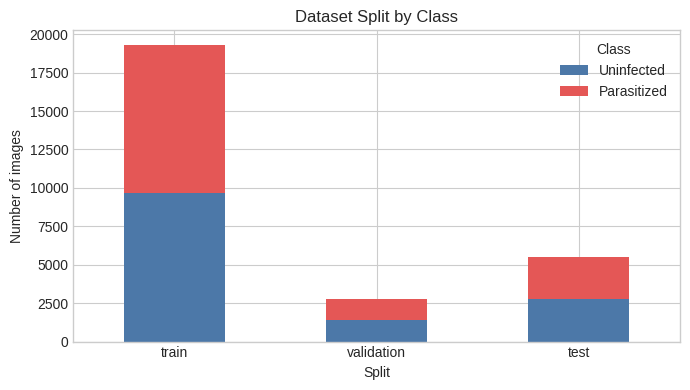

In [20]:
ax = split_class_counts[
    ["Uninfected", "Parasitized"]
].plot(
    kind="bar",
    stacked=True,
    figsize=(7, 4),
    color=[CLASS_COLORS["Uninfected"], CLASS_COLORS["Parasitized"]],
)

ax.set_title("Dataset Split by Class")
ax.set_xlabel("Split")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Class")

plt.tight_layout()
plt.savefig(PROJECT_DIR / "split_class_distribution.png", dpi=200)
plt.show()


In [21]:
patients_by_split = {
    split: set(
        image_df.loc[
            image_df["split"] == split,
            "official_patient_id",
        ]
    )
    for split in ["train", "validation", "test"]
}

print(
    "Train-validation patient overlap:",
    len(patients_by_split["train"] & patients_by_split["validation"]),
)

print(
    "Train-test patient overlap:",
    len(patients_by_split["train"] & patients_by_split["test"]),
)

print(
    "Validation-test patient overlap:",
    len(patients_by_split["validation"] & patients_by_split["test"]),
)

Train-validation patient overlap: 201
Train-test patient overlap: 201
Validation-test patient overlap: 201


### Split limitation: patient overlap

All 201 mapped patient identifiers occur in the training, validation, and test
subsets. The selected paper uses an image-level split, so cells from one
patient can appear in multiple subsets. We retain this protocol to reproduce
the paper fairly, but the resulting metrics may be optimistic and must not be
presented as patient-independent generalization.


In [22]:
manifest_columns = [
    "relative_path",
    "filename",
    "class_name",
    "label",
    "width",
    "height",
    "sha256",
    "official_patient_id",
    "split",
]

MANIFEST_PATH = PROJECT_DIR / "split_manifest.csv"

image_df[manifest_columns].to_csv(
    MANIFEST_PATH,
    index=False,
)

print("Manifest saved to:", MANIFEST_PATH)
print("Rows saved:", len(image_df))
print("File size:", round(MANIFEST_PATH.stat().st_size / 1024**2, 2), "MB")

Manifest saved to: /content/drive/MyDrive/malaria_danet/split_manifest.csv
Rows saved: 27558
File size: 5.48 MB


## 4. Preprocessing and data loaders

Resize inputs to 224 × 224, apply the paper's training augmentations, and
construct the PyTorch datasets and data loaders used by the DANet model.


In [23]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=15),
    transforms.RandomHorizontalFlip(p=0.20),
    transforms.RandomVerticalFlip(p=0.20),
    transforms.ToTensor(),
])

evaluation_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

print(train_transform)
print(evaluation_transform)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    RandomHorizontalFlip(p=0.2)
    RandomVerticalFlip(p=0.2)
    ToTensor()
)
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


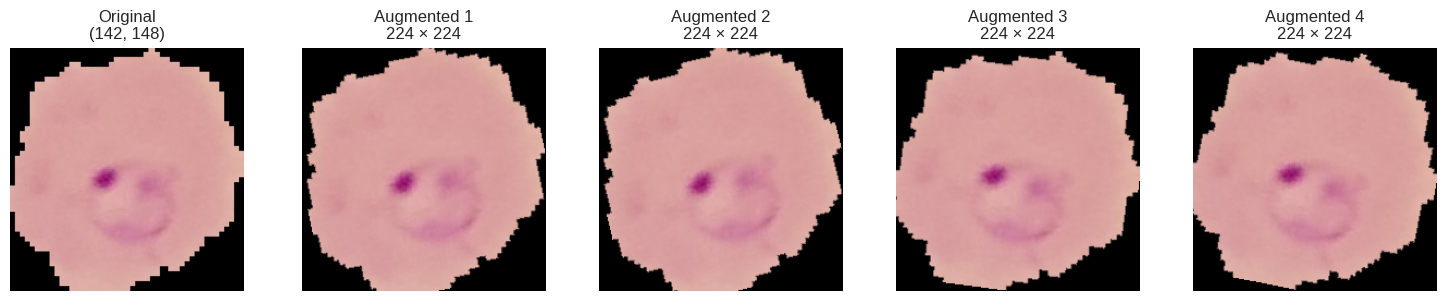

In [24]:
sample_row = image_df[
    image_df["class_name"] == "Parasitized"
].iloc[0]

with Image.open(IMAGE_ROOT / sample_row["relative_path"]) as image:
    original_image = image.convert("RGB")

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

axes[0].imshow(original_image)
axes[0].set_title(f"Original\n{original_image.size}")
axes[0].axis("off")

for index in range(1, 5):
    augmented_tensor = train_transform(original_image)
    augmented_image = augmented_tensor.permute(1, 2, 0)

    axes[index].imshow(augmented_image)
    axes[index].set_title(f"Augmented {index}\n224 × 224")
    axes[index].axis("off")

plt.tight_layout()
plt.savefig(PROJECT_DIR / "augmentation_examples.png", dpi=200)
plt.show()

In [25]:
from torch.utils.data import Dataset


class MalariaDataset(Dataset):
    def __init__(self, dataframe, image_root, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = self.image_root / row["relative_path"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = int(row["label"])
        return image, label


In [26]:
train_dataset = MalariaDataset(
    image_df[image_df["split"] == "train"],
    IMAGE_ROOT,
    train_transform,
)

validation_dataset = MalariaDataset(
    image_df[image_df["split"] == "validation"],
    IMAGE_ROOT,
    evaluation_transform,
)

test_dataset = MalariaDataset(
    image_df[image_df["split"] == "test"],
    IMAGE_ROOT,
    evaluation_transform,
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Test samples:", len(test_dataset))

Training samples: 19290
Validation samples: 2756
Test samples: 5512


In [27]:
sample_image, sample_label = train_dataset[0]

print("Tensor shape:", sample_image.shape)
print("Tensor dtype:", sample_image.dtype)
print("Pixel range:", float(sample_image.min()), "to", float(sample_image.max()))
print("Label:", sample_label)

Tensor shape: torch.Size([3, 224, 224])
Tensor dtype: torch.float32
Pixel range: 0.0 to 0.8823529481887817
Label: 0


In [28]:
import random

import numpy as np
from torch.utils.data import DataLoader

BATCH_SIZE = 64


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


train_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=train_generator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))


Training batches: 302
Validation batches: 44
Test batches: 87


In [29]:
batch_images, batch_labels = next(iter(train_loader))

print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)
print("Image dtype:", batch_images.dtype)
print("Pixel range:", float(batch_images.min()), "to", float(batch_images.max()))
print("Labels in batch:", torch.bincount(batch_labels, minlength=2))

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Pixel range: 0.0 to 0.9529411792755127
Labels in batch: tensor([37, 27])


In [30]:
train_image_1, _ = train_dataset[0]
train_image_2, _ = train_dataset[0]

val_image_1, _ = validation_dataset[0]
val_image_2, _ = validation_dataset[0]

print(
    "Training sample identical across two loads:",
    torch.equal(train_image_1, train_image_2),
)

print(
    "Validation sample identical across two loads:",
    torch.equal(val_image_1, val_image_2),
)

Training sample identical across two loads: False
Validation sample identical across two loads: True


### Pipeline verification

- Every transformed image has shape `3 x 224 x 224` and uses `float32` values
  scaled to the 0 to 1 range.
- Training transformations are stochastic, while validation and test
  preprocessing is deterministic.
- The data loaders expose 302 training batches, 44 validation batches, and 87
  test batches at batch size 64.
- The saved manifest fixes the exact membership of every subset.


## 5. Reproducibility artifacts

Save the split manifest, pipeline configuration, dataset summary, and figures
required for the remaining milestone work.


In [31]:
import json

data_config = {
    "dataset": "NIH/NLM Malaria Cell Images",
    "dataset_url": DATASET_URL,
    "base_paper": (
        "DANet: A Lightweight Dilated Attention Network for Malaria "
        "Parasite Detection"
    ),
    "base_paper_doi": "10.1038/s41598-025-20402-1",
    "baseline_variant": "DANet-S with LogSoftMax",
    "total_images": 27558,
    "class_mapping": CLASS_TO_LABEL,
    "split_protocol": "stratified image-level split",
    "split_seed": SEED,
    "split_ratios": {
        "train": 0.70,
        "validation": 0.10,
        "test": 0.20,
    },
    "split_counts": {
        "train": 19290,
        "validation": 2756,
        "test": 5512,
    },
    "input_size": [224, 224],
    "pixel_scaling": "[0, 255] to [0, 1]",
    "training_augmentation": {
        "rotation_degrees": 15,
        "horizontal_flip_probability": 0.20,
        "vertical_flip_probability": 0.20,
    },
    "batch_size": 64,
    "unreadable_images": 0,
    "exact_duplicate_groups": 0,
    "unique_official_patient_ids": 201,
    "patient_overlap_note": (
        "All 201 mapped patient identifiers occur in train, validation, "
        "and test because the base paper uses an image-level split."
    ),
}

CONFIG_PATH = PROJECT_DIR / "data_config.json"

with open(CONFIG_PATH, "w") as file:
    json.dump(data_config, file, indent=2)

print("Configuration saved to:", CONFIG_PATH)


Configuration saved to: /content/drive/MyDrive/malaria_danet/data_config.json


In [32]:
saved_manifest = pd.read_csv(MANIFEST_PATH)

assert len(saved_manifest) == 27558
assert saved_manifest["split"].value_counts().to_dict() == {
    "train": 19290,
    "test": 5512,
    "validation": 2756,
}
assert saved_manifest["official_patient_id"].isna().sum() == 0

print("Manifest reload check passed.")
print(saved_manifest["split"].value_counts())

Manifest reload check passed.
split
train         19290
test           5512
validation     2756
Name: count, dtype: int64


In [33]:
member1_summary = """# Dataset Preparation Summary

- Dataset: NIH/NLM Malaria Cell Images
- Task: Binary classification of parasitized and uninfected cells
- Total images: 27,558
- Parasitized images: 13,779
- Uninfected images: 13,779
- Unreadable images: 0
- Exact duplicate groups: 0
- Original image sizes: variable
- Model input size: 224 × 224 RGB
- Pixel scaling: [0, 255] to [0, 1]
- Label mapping: Uninfected = 0, Parasitized = 1
- Split: 70% train, 10% validation, 20% test
- Training images: 19,290
- Validation images: 2,756
- Test images: 5,512
- Split seed: 42
- Batch size: 64
- Training augmentation: rotation ±15°, horizontal flip p=0.20,
  vertical flip p=0.20
- Validation/test augmentation: none
- Official patient identifiers found: 201

## Important limitation

The paper-matched split is performed at image level. All 201 patient
identifiers occur in the training, validation, and test subsets. This creates
patient overlap and may produce optimistic evaluation results. The split is
retained for faithful reproduction of the selected DANet paper and must be
reported as a limitation.
"""

SUMMARY_PATH = PROJECT_DIR / "member1_data_summary.md"

with open(SUMMARY_PATH, "w") as file:
    file.write(member1_summary)

print("Summary saved to:", SUMMARY_PATH)

Summary saved to: /content/drive/MyDrive/malaria_danet/member1_data_summary.md


In [34]:
expected_artifacts = [
    "split_manifest.csv",
    "data_config.json",
    "member1_data_summary.md",
    "class_distribution.png",
    "sample_images.png",
    "image_size_distribution.png",
    "split_class_distribution.png",
    "augmentation_examples.png",
]

for artifact_name in expected_artifacts:
    artifact_path = PROJECT_DIR / artifact_name
    status = "FOUND" if artifact_path.exists() else "MISSING"
    print(f"{status:7}  {artifact_name}")

FOUND    split_manifest.csv
FOUND    data_config.json
FOUND    member1_data_summary.md
FOUND    class_distribution.png
FOUND    sample_images.png
FOUND    image_size_distribution.png
FOUND    split_class_distribution.png
FOUND    augmentation_examples.png
